# Credit Card Fraud Detection — Decision Tree vs Random Forest

**Workflow:** Library import → data sourcing → preprocessing → feature selection → data splitting → model selection → model training → evaluation → prediction.

**Dataset:** Kaggle Credit Card Fraud Detection (`creditcard.csv`). Download it and place it in the same folder as this notebook. `Class` is the target (0 = legitimate, 1 = fraud).

**Note:** Fraud datasets are highly imbalanced. Accuracy is included, but compare precision, recall and F1-score too. Run the notebook to calculate actual results.

## 1. Library import

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score
)

## 2. Data sourcing

In [3]:
# Dataset: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
df = pd.read_csv("creditcard.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nTarget distribution:")
display(df["Class"].value_counts())
print("\nMissing values:", int(df.isnull().sum().sum()))

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Target distribution:


Class
0    284315
1       492
Name: count, dtype: int64


Missing values: 0


## 3. Data preprocessing

In [4]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Separate features and target
X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

print("Rows after removing duplicates:", len(df))
print("Missing feature values before imputation:", int(X.isnull().sum().sum()))
print("Fraud percentage:", round(y.mean() * 100, 4), "%")

Rows after removing duplicates: 283726
Missing feature values before imputation: 0
Fraud percentage: 0.1667 %


## 4. Feature selection

In [5]:
# Use all available predictor columns and exclude the target to avoid leakage.
selected_features = X.columns.tolist()
X = X[selected_features]

print("Number of selected features:", len(selected_features))
print(selected_features)

Number of selected features: 30
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


## 5. Data splitting

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Fit imputation only on training data to avoid data leakage.
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=selected_features, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=selected_features, index=X_test.index)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))

Training rows: 226980
Testing rows: 56746
Training fraud cases: 378
Testing fraud cases: 95


## 6. Model 1 — Decision Tree

In [7]:
# A single tree is easy to interpret, but can overfit.
dt_model = DecisionTreeClassifier(
    max_depth=8,
    class_weight="balanced",
    random_state=42
)
print(dt_model)

DecisionTreeClassifier(class_weight='balanced', max_depth=8, random_state=42)


## 7. Train Decision Tree

In [8]:
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]
print("Decision Tree training complete.")

Decision Tree training complete.


## 8. Evaluate Decision Tree

,Model,Accuracy (%),Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,99.1471,0.1405,0.8,0.239,0.9074


              precision    recall  f1-score   support

  Legitimate       1.00      0.99      1.00     56651
       Fraud       0.14      0.80      0.24        95

    accuracy                           0.99     56746
   macro avg       0.57      0.90      0.62     56746
weighted avg       1.00      0.99      0.99     56746



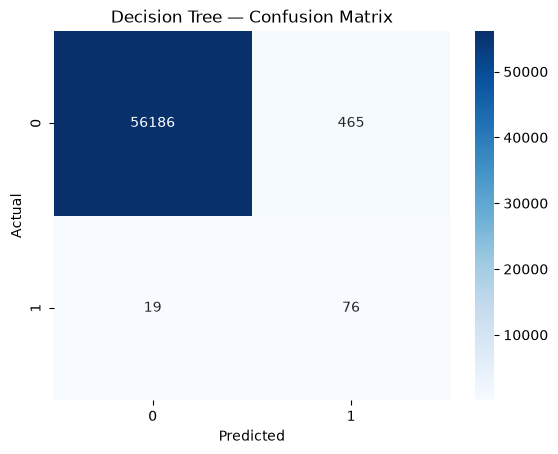

In [9]:
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

dt_results = evaluate_model("Decision Tree", y_test, dt_pred, dt_prob)
display(pd.DataFrame([dt_results]).round(4))
print(classification_report(y_test, dt_pred, target_names=["Legitimate", "Fraud"], zero_division=0))

sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Decision Tree — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 9. Model 2 — Random Forest

In [10]:
# Random Forest combines many trees, often reducing overfitting vs a single tree.
rf_model = RandomForestClassifier(
    n_estimators=150,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
print(rf_model)

RandomForestClassifier(class_weight='balanced_subsample', n_estimators=150,
                       n_jobs=-1, random_state=42)


## 10. Train Random Forest

In [11]:
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]
print("Random Forest training complete.")

Random Forest training complete.


## 11. Evaluate Random Forest

,Model,Accuracy (%),Precision,Recall,F1-score,ROC-AUC
0,Random Forest,99.9489,0.9853,0.7053,0.8221,0.9292


              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.99      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746



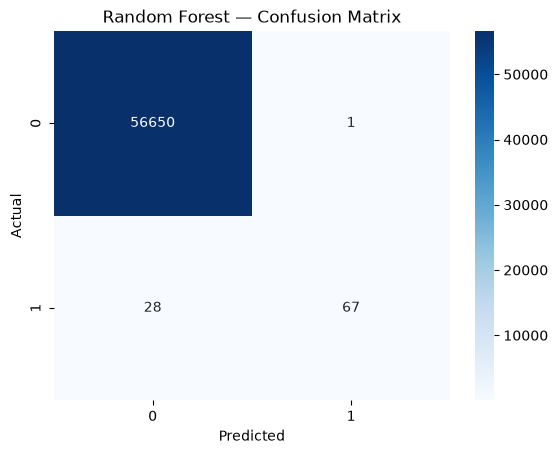

In [12]:
rf_results = evaluate_model("Random Forest", y_test, rf_pred, rf_prob)
display(pd.DataFrame([rf_results]).round(4))
print(classification_report(y_test, rf_pred, target_names=["Legitimate", "Fraud"], zero_division=0))

sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 12. Compare both models

,Accuracy (%),Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Decision Tree,99.1471,0.1405,0.8000,0.2390,0.9074
Random Forest,99.9489,0.9853,0.7053,0.8221,0.9292


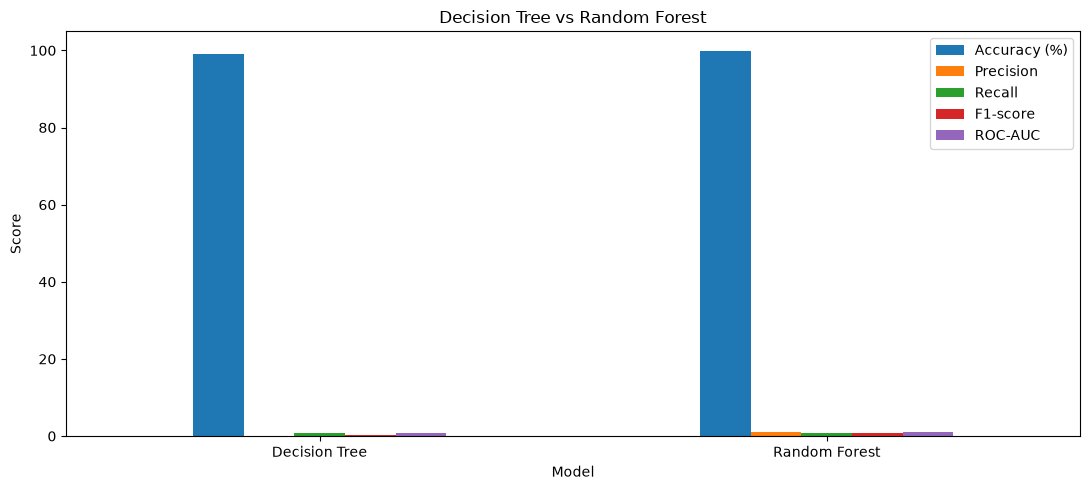

In [16]:
comparison = pd.DataFrame([dt_results, rf_results]).set_index("Model")
display(comparison.round(4))

comparison[["Accuracy (%)", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Decision Tree vs Random Forest")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

